# Ann's 21 Oct poster comments: Addis vs the IMPROVE look-alikes, and the seasons

Ann's comments on `Ahmad_aaar_poster_2026_v2_AMD.pptx` asked for analyses rather than poster text:

* **C7.** The IMPROVE filters whose spectra most resemble Addis "fail in a different direction" from Addis. Put the 97
  look-alike spectra beside the Addis spectra, raw and baseline-corrected; show Figures 4b and 5b in mass units; baseline
  the look-alikes and predict them, and see whether the intercepts still have opposite signs.
* **C8.** Kiremt, the season with the most wood and charcoal smoke, is predicted best by its season-specific
  calibration, and Dry (mostly diesel) is not. Look at the IMPROVE and Addis spectra by season.
* **C9.** Why the per-season fits have smaller slopes and different intercepts from the fit of all seasons together,
  and what the season-specific predictions give when pooled.

Inputs are the ones the poster uses: the frozen spline (AIRSpec) run and its raw-spectra bundles
(`output/tables/vibes_colab_bundle*/`), the rank-70 meeting tables, and the 189 Addis filters with a published SPARTAN
FTIR EC. Deming fits use the poster's error models: the Addis λ (σx from HIPS uncertainty, σy 0.531) on Addis panels and
the IMPROVE look-alike error model of `run_meeting_followup_20260917.analog_panels` on look-alike panels. No OLS.

Two calibrations are compared on both sets of filters:

* **SPARTAN-like (raw):** raw spectra 4000-500 cm⁻¹, lot-251 IMPROVE training split (the 97 look-alikes are from
  held-out sites), k = 18, which reproduces SPARTAN's published Addis EC (`docs/spartan-ftir-ec-recreation.md`). One IMPROVE
  filter with a corrupt raw spectrum (TONT1 2022-11-19) is excluded.
* **Baseline-corrected (spline):** the poster's all-IMPROVE lot-251 calibration on spline-corrected spectra
  (1425-4000 cm⁻¹), k chosen by the site-held-out rule (8).

In [1]:
import sys
sys.path.insert(0, './scripts')
sys.path.insert(0, './workflows')

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cross_decomposition import PLSRegression

import plotting  # noqa: F401  (applies the default white style)
import analog_bias as ab
import pls_ksweep as pk
import raw_vs_spline_20261020 as rv
import run_meeting_followup_20260917 as rmf
from config import ETHIOPIA_SEASONS

FIG = Path('output/plots/ann_followup_20261021')
FIG.mkdir(parents=True, exist_ok=True)
M = Path('output/tables/vibes_fullrange/gallery_rank70_20261002/meeting')
pd.set_option('display.width', 200)
SEASONS = list(ETHIOPIA_SEASONS)
SCOL = {s: ETHIOPIA_SEASONS[s]['color'] for s in SEASONS}
C_ADDIS, C_AN, C_GREY = '#C49442', '#B23327', '#8F8C84'

ctx = ab.load_context(fullrange=False)
cases = pd.read_csv(ab.RUN / 'cases.csv')
lib = ctx.lib
wn_full = np.load(rv.BUNDLE_FULL / 'data/wn.npy')
wn_cut = np.load(ab.RUN / 'wn.npy')
X_raw = rv.raw_rows(cases, lib.row, rv.BUNDLE_FULL)
XA_raw = rv.raw_rows(cases, ctx.addis.row, rv.BUNDLE_FULL)
X_spl, XA_spl = ctx.X['AIRSpec'], ctx.XA['AIRSpec']
qc = rv.qc_keep(rv.raw_rows(cases, lib.row), ctx)

# the 189 poster Addis filters, with SPARTAN's published (deployed) EC
dep = pd.read_csv(rv.DEPLOYED)
dep = dep[dep.fit_id.eq('deployed|SPARTAN|current SPARTAN calibration')].dropna(subset=['ftir_ec_ugm3', 'Fabs'])
coh = ctx.addis.MediaId.isin(dep.MediaId).to_numpy()
A = ctx.addis.loc[coh].copy().reset_index(drop=True)
A['vol'] = A.Volume_m3.astype(float)
A['hips'] = A.Fabs / ab.MAC_VALUE                       # µg/m³
A['spartan'] = A[['MediaId']].merge(dep[['MediaId', 'ftir_ec_ugm3']], on='MediaId', how='left').ftir_ec_ugm3.to_numpy()
XA_raw, XA_spl = XA_raw[coh], XA_spl[coh]
A['ec_ug'] = A.hips * A.vol                             # HIPS EC on the filter, µg

# IMPROVE look-alike sets from the rank-70 meeting run (spline selection, locked mask)
an = pd.read_csv(M / 'analog_predictions.csv')
FIT = 'allimprove|AIRSpec|all-IMPROVE lot 251'
pos = pd.Series(np.arange(len(lib)), index=lib.filter_id.astype(int).to_numpy())
def rows_of(group, role=None):
    q = an[an.fit_id.eq(f'{FIT}|{group}')]
    if role:
        q = q[q.role.eq(role)]
    return pos.loc[q.filter_id.astype(int)].to_numpy()
L97 = rows_of('All Addis', 'test')
LSEA = {s: rows_of(s) for s in SEASONS}
assert len(L97) == 97 and lib.split.to_numpy()[L97].tolist().count('test') == 97
lib_ec_ug = lib.y.to_numpy(float)                       # TOR EC on the filter, µg
lib_vol = lib.tor_volume_m3.to_numpy(float)
lib_hips = lib.fabs_Mm1.to_numpy(float) / ab.MAC_VALUE  # µg/m³
print(f'Addis: {len(A)} filters; look-alikes: {len(L97)} (held-out sites); seasonal look-alike sets: '
      + ', '.join(f'{s.split()[0]} {len(v)}' for s, v in LSEA.items()))

Filter dataset loaded: 44493 measurements
Sites: ['CHTS' 'ETAD' 'INDH' 'USPA']
Date range: 2013-06-28 to 2024-12-08


Addis: 189 filters; look-alikes: 97 (held-out sites); seasonal look-alike sets: Dry 500, Belg 500, Kiremt 500


## A. The same calibration on Addis and on the look-alikes

Figure 4b (Addis) uses SPARTAN's own calibration, which works on raw spectra; Figure 5b (look-alikes) uses the poster's
baseline-corrected calibration. So the poster compares two different calibrations on two different sets of filters.
Below, each calibration is applied to both sets.

In [2]:
lot = lib.lot.eq(251).to_numpy()
train = lib.split.eq('train').to_numpy()

# baseline-corrected: the poster's calibration (fit_cohort with the protocol's own k), as run_meeting_followup does it
idx = np.flatnonzero(lot)
f_spl = ab.fit_cohort(X_spl[idx], lib.y.to_numpy()[idx], lib.Site.to_numpy()[idx], train=train[idx])
test_lot = np.flatnonzero(lib.split.eq('test').to_numpy() & lot)
rmse_spl = ab.xy_stats(lib.y.to_numpy()[test_lot], f_spl.predict(X_spl[test_lot]))['RMSE']

# raw SPARTAN-like: k 18 on the lot-251 training split, TONT1 excluded
tr_raw = np.flatnonzero(lot & train & qc)
m_raw = PLSRegression(n_components=18, scale=False).fit(X_raw[tr_raw], lib.y.to_numpy()[tr_raw])
raw_pred = lambda X: m_raw.predict(X).ravel()
rmse_raw = ab.xy_stats(lib.y.to_numpy()[test_lot], raw_pred(X_raw[test_lot]))['RMSE']

P = {  # µg/m³
    ('Addis', 'SPARTAN published'): A.spartan.to_numpy(),
    ('Addis', 'SPARTAN-like raw, k 18'): raw_pred(XA_raw) / A.vol.to_numpy(),
    ('Addis', f'baseline-corrected, k {f_spl.k}'): f_spl.predict(XA_spl) / A.vol.to_numpy(),
    ('look-alikes', 'SPARTAN-like raw, k 18'): raw_pred(X_raw[L97]) / lib_vol[L97],
    ('look-alikes', f'baseline-corrected, k {f_spl.k}'): f_spl.predict(X_spl[L97]) / lib_vol[L97],
}
RMSE = {'SPARTAN-like raw, k 18': rmse_raw, f'baseline-corrected, k {f_spl.k}': rmse_spl}

def addis_fit(y, scale=None):
    x = A.hips.to_numpy() if scale is None else A.hips.to_numpy() * scale
    yy = y if scale is None else y * scale
    sx = ctx.sigma_x * (1 if scale is None else np.median(scale))
    sy = ab.SIGMA_Y_PROXY * (1 if scale is None else np.median(scale))
    return ab.xy_stats(x, yy, lam=ctx.lam, sigma_x=sx, sigma_y=sy)

def lookalike_fit(y, rmse_ug, per_filter=False):
    if not per_filter:
        return rmf.analog_panels(ctx, L97, y, rmse_ug, boot=False)['ftir_vs_fabs']
    v = lib_vol[L97]
    x, yy = lib_hips[L97] * v, y * v
    rel = rmf.ref_rel_uncertainty(ctx)
    sx, sy = rel * np.median(x), rmse_ug
    return ab.xy_stats(x, yy, lam=(sy / sx) ** 2, sigma_x=sx, sigma_y=sy)

rows = []
for (who, cal), y in P.items():
    for units, per in (('µg/m³', False), ('µg per filter', True)):
        if who == 'Addis':
            st = addis_fit(y, A.vol.to_numpy() if per else None)
        else:
            st = lookalike_fit(y, RMSE[cal], per_filter=per)
        rows.append({'filters': who, 'calibration': cal, 'units': units, 'slope': st['deming_slope'],
                     'intercept': st['deming_intercept'], 'R2': st['R2'], 'n': st['n']})
fits = pd.DataFrame(rows)
display(fits.round(2))
# reproduction checks against the poster
chk = fits[(fits.units == 'µg/m³')].set_index(['filters', 'calibration'])
assert abs(chk.loc[('Addis', 'SPARTAN published'), 'slope'] - 2.30) < 0.01
assert abs(chk.loc[('Addis', f'baseline-corrected, k {f_spl.k}'), 'intercept'] + 1.21) < 0.01
assert abs(chk.loc[('look-alikes', f'baseline-corrected, k {f_spl.k}'), 'slope'] - 0.46) < 0.01
print(f'baseline-corrected k = {f_spl.k}; held-out IMPROVE RMSE: raw {rmse_raw:.2f} µg, spline {rmse_spl:.2f} µg')

,filters,calibration,units,slope,intercept,R2,n
0,Addis,SPARTAN published,µg/m³,2.30,-6.09,0.78,189
1,Addis,SPARTAN published,µg per filter,2.29,-43.82,0.79,189
2,Addis,"SPARTAN-like raw, k 18",µg/m³,2.36,-6.30,0.78,189
3,Addis,"SPARTAN-like raw, k 18",µg per filter,2.35,-45.37,0.78,189
4,Addis,"baseline-corrected, k 8",µg/m³,0.59,-1.21,0.69,189
5,Addis,"baseline-corrected, k 8",µg per filter,0.59,-8.58,0.69,189
6,look-alikes,"SPARTAN-like raw, k 18",µg/m³,0.70,0.01,0.68,97
7,look-alikes,"SPARTAN-like raw, k 18",µg per filter,0.70,0.25,0.68,97
8,look-alikes,"baseline-corrected, k 8",µg/m³,0.46,0.11,0.52,97
9,look-alikes,"baseline-corrected, k 8",µg per filter,0.46,3.44,0.52,97


baseline-corrected k = 8; held-out IMPROVE RMSE: raw 2.99 µg, spline 3.31 µg


## B. Figures 4b and 5b in µg per filter

Both axes multiplied by each filter's own volume of air (Addis about 7.3 m³, IMPROVE about 30 m³), so Addis and the
look-alikes sit on one mass scale. Left: the SPARTAN-like raw calibration; right: the baseline-corrected one. Each panel
has both sets of filters, so it shows directly whether they fall on one curve.

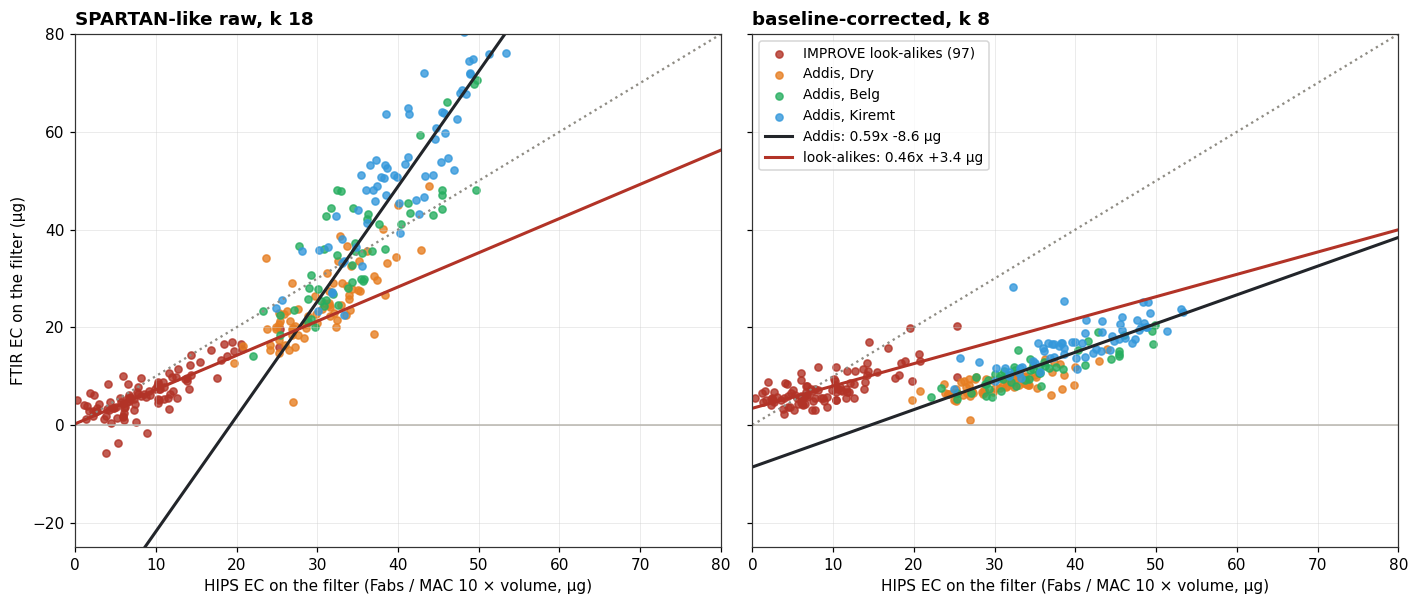

HIPS EC on the filter, µg: Addis 34.1 (IQR 29.7-40.0) | look-alikes 7.8 (IQR 5.2-11.8)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), sharex=True, sharey=True)
cals = ['SPARTAN-like raw, k 18', f'baseline-corrected, k {f_spl.k}']
lim = 80
for ax, cal in zip(axes, cals):
    ya, yl = P[('Addis', cal)] * A.vol.to_numpy(), P[('look-alikes', cal)] * lib_vol[L97]
    xa, xl = A.ec_ug.to_numpy(), lib_hips[L97] * lib_vol[L97]
    ax.scatter(xl, yl, s=22, color=C_AN, alpha=.8, label=f'IMPROVE look-alikes ({len(L97)})')
    for s in SEASONS:
        m = A.season.eq(s).to_numpy()
        ax.scatter(xa[m], ya[m], s=22, color=SCOL[s], alpha=.8, label=f'Addis, {s.split()[0]}')
    xs = np.array([0, lim])
    ax.plot(xs, xs, ls=':', color=C_GREY)
    ax.axhline(0, color='#B8B5AE', lw=1)
    for who, col in (('Addis', '#22252A'), ('look-alikes', C_AN)):
        r = fits[(fits.filters == who) & (fits.calibration == cal) & (fits.units == 'µg per filter')].iloc[0]
        ax.plot(xs, r.intercept + r.slope * xs, color=col, lw=2,
                label=f'{who}: {r.slope:.2f}x {r.intercept:+.1f} µg')
    ax.set_xlim(0, lim); ax.set_ylim(-25, lim)
    ax.set_title(cal, loc='left', fontweight='bold')
    ax.set_xlabel('HIPS EC on the filter (Fabs / MAC 10 × volume, µg)')
axes[0].set_ylabel('FTIR EC on the filter (µg)')
axes[1].legend(loc='upper left', fontsize=9)
fig.tight_layout(); fig.savefig(FIG / 'B_mass_units.png', dpi=200, bbox_inches='tight'); plt.show()
q = lambda v: f'{np.median(v):.1f} (IQR {np.percentile(v, 25):.1f}-{np.percentile(v, 75):.1f})'
print('HIPS EC on the filter, µg: Addis', q(A.ec_ug), '| look-alikes', q(lib_hips[L97] * lib_vol[L97]))

## C. Addis vs the 97 look-alike spectra (C7)

Median spectrum and interquartile band for each set. Top: raw absorbance over 4000-500 cm⁻¹ (what the SPARTAN-like
calibration sees). Bottom: spline baseline-corrected, 1425-4000 cm⁻¹ (what the poster's calibration sees). Left: absorbance
as measured. Right: divided by each filter's EC mass (Addis: HIPS EC; IMPROVE: TOR EC), so the curves compare composition
per µg of EC rather than loading.

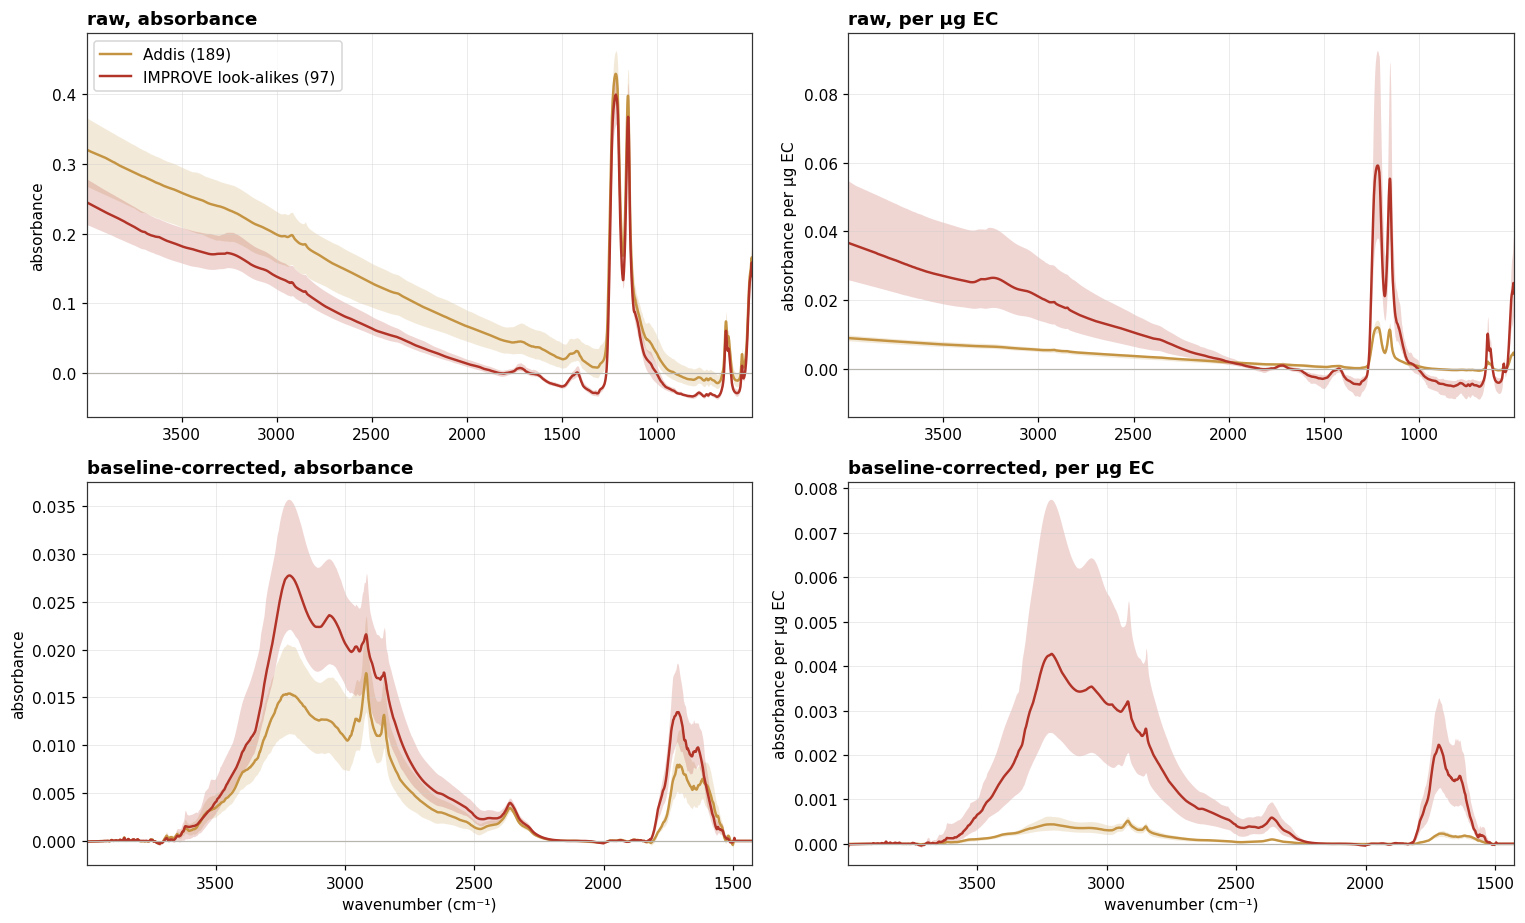

In [4]:
def band(ax, wn, X, color, label, norm=None):
    Y = X if norm is None else X / norm[:, None]
    lo, med, hi = np.percentile(Y, [25, 50, 75], axis=0)
    ax.fill_between(wn, lo, hi, color=color, alpha=.2, lw=0)
    ax.plot(wn, med, color=color, lw=1.6, label=label)

lib_norm = lib_ec_ug
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for r, (wn, XA_, XL, kind) in enumerate([(wn_full, XA_raw, X_raw[L97], 'raw'), (wn_cut, XA_spl, X_spl[L97], 'baseline-corrected')]):
    for c, per_ec in enumerate((False, True)):
        ax = axes[r, c]
        band(ax, wn, XA_, C_ADDIS, f'Addis ({len(A)})', A.ec_ug.to_numpy() if per_ec else None)
        band(ax, wn, XL, C_AN, f'IMPROVE look-alikes ({len(L97)})', lib_norm[L97] if per_ec else None)
        ax.set_xlim(wn.max(), wn.min()); ax.axhline(0, color='#B8B5AE', lw=.8)
        ax.set_title(f'{kind}, {"per µg EC" if per_ec else "absorbance"}', loc='left', fontweight='bold')
        ax.set_ylabel('absorbance per µg EC' if per_ec else 'absorbance')
        if r == 1:
            ax.set_xlabel('wavenumber (cm⁻¹)')
axes[0, 0].legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIG / 'C_spectra_lookalikes.png', dpi=200, bbox_inches='tight'); plt.show()

Band areas per µg EC (baseline-corrected spectra, summed absorbance in each band ÷ EC on the filter), as
a numerical version of the bottom-right panel. A ratio below 1 means Addis has less of that band per unit EC than the
look-alikes.

In [5]:
BANDS = {'O–H / N–H 3000–3600': (3600, 3000), 'C–H 2800–3000': (3000, 2800), 'carbonyl 1650–1800': (1800, 1650),
         '1600 band 1500–1650': (1650, 1500), 'high-wn baseline 3600–4000': (4000, 3600)}
def band_per_ec(X, norm):
    out = {}
    for name, (hi_, lo_) in BANDS.items():
        sel = (wn_cut <= hi_) & (wn_cut > lo_)
        out[name] = np.median(X[:, sel].sum(1) / norm)
    return out
tab = pd.DataFrame({'Addis': band_per_ec(XA_spl, A.ec_ug.to_numpy()),
                    'look-alikes': band_per_ec(X_spl[L97], lib_norm[L97]),
                    'all lot-251 IMPROVE': band_per_ec(X_spl[lot & (lib_norm > 0.5)], lib_norm[lot & (lib_norm > 0.5)])})
tab['Addis / look-alikes'] = tab['Addis'] / tab['look-alikes']
display(tab.round(4))

,Addis,look-alikes,all lot-251 IMPROVE,Addis / look-alikes
O–H / N–H 3000–3600,0.1272,1.1372,1.4078,0.1118
C–H 2800–3000,0.0534,0.4175,0.5383,0.1279
carbonyl 1650–1800,0.0167,0.1660,0.2306,0.1007
1600 band 1500–1650,0.0114,0.0653,0.0793,0.1748
high-wn baseline 3600–4000,0.0015,0.0041,0.0029,0.3586


## D. By season (C8)

Each Addis season against that season's IMPROVE look-alike set (the 500 filters its season-specific calibration was
built from). Top: raw absorbance; bottom: baseline-corrected, per µg EC.

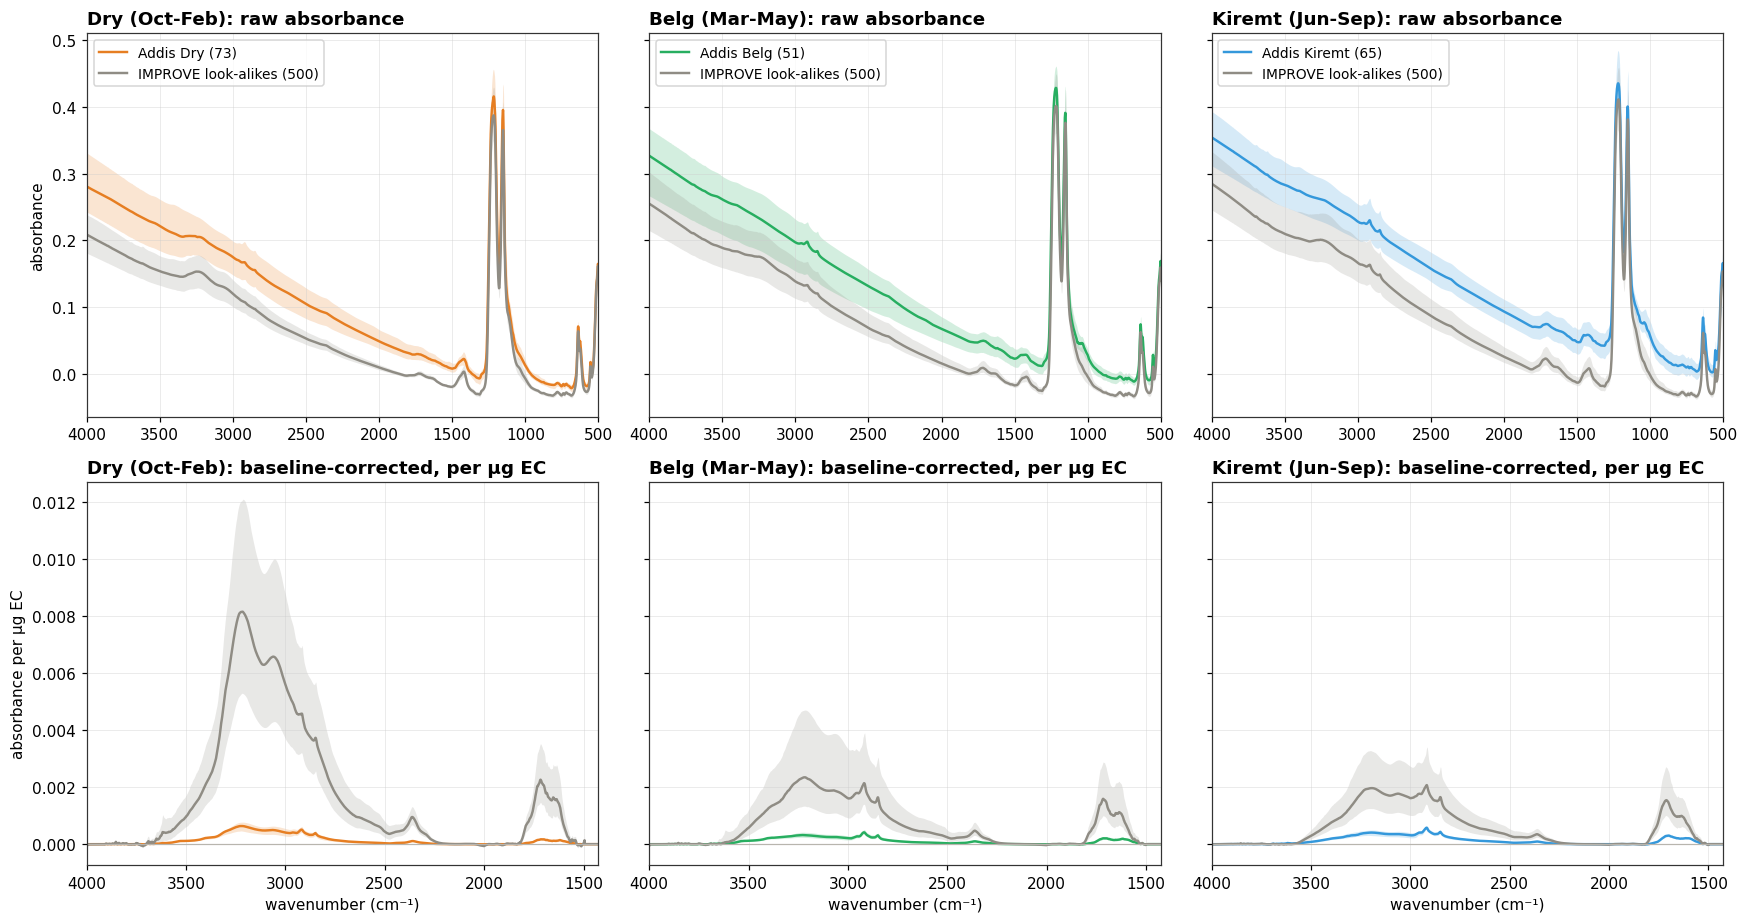

,Addis EC µg (median),look-alike EC µg (median),look-alike TOR OC/EC (median),O–H / N–H 3000–3600 Addis/look-alike,C–H 2800–3000 Addis/look-alike,carbonyl 1650–1800 Addis/look-alike,1600 band 1500–1650 Addis/look-alike,high-wn baseline 3600–4000 Addis/look-alike
season,,,,,,,,
Dry (Oct-Feb),30.89,3.71,4.70,0.08,0.09,0.07,0.12,0.10
Belg (Mar-May),34.26,7.98,4.28,0.15,0.16,0.13,0.22,0.97
Kiremt (Jun-Sep),40.13,13.35,3.60,0.21,0.23,0.18,0.28,5.68


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharey='row')
for c, s in enumerate(SEASONS):
    ma = A.season.eq(s).to_numpy()
    L = LSEA[s]
    ax = axes[0, c]
    band(ax, wn_full, XA_raw[ma], SCOL[s], f'Addis {s.split()[0]} ({ma.sum()})')
    band(ax, wn_full, X_raw[L], C_GREY, f'IMPROVE look-alikes ({len(L)})')
    ax.set_xlim(4000, 500); ax.set_title(f'{s}: raw absorbance', loc='left', fontweight='bold')
    ax = axes[1, c]
    band(ax, wn_cut, XA_spl[ma], SCOL[s], f'Addis {s.split()[0]}', A.ec_ug.to_numpy()[ma])
    band(ax, wn_cut, X_spl[L], C_GREY, 'IMPROVE look-alikes', lib_norm[L])
    ax.set_xlim(4000, 1425); ax.axhline(0, color='#B8B5AE', lw=.8)
    ax.set_title(f'{s}: baseline-corrected, per µg EC', loc='left', fontweight='bold')
    ax.set_xlabel('wavenumber (cm⁻¹)')
    axes[0, c].legend(loc='upper left', fontsize=9)
axes[0, 0].set_ylabel('absorbance'); axes[1, 0].set_ylabel('absorbance per µg EC')
fig.tight_layout(); fig.savefig(FIG / 'D_spectra_by_season.png', dpi=200, bbox_inches='tight'); plt.show()

rows = []
for s in SEASONS:
    ma = A.season.eq(s).to_numpy(); L = LSEA[s]
    a_, l_ = band_per_ec(XA_spl[ma], A.ec_ug.to_numpy()[ma]), band_per_ec(X_spl[L], lib_norm[L])
    rows.append({'season': s, 'Addis EC µg (median)': np.median(A.ec_ug[ma]),
                 'look-alike EC µg (median)': np.median(lib_norm[L]),
                 'look-alike TOR OC/EC (median)': np.median(lib.tor_oc_ec.to_numpy()[L]),
                 **{f'{k} Addis/look-alike': a_[k] / l_[k] for k in BANDS}})
display(pd.DataFrame(rows).set_index('season').round(2))

## E. Seasons pooled vs separate (C9)

Ann's question: every season's fit has a smaller slope than the fit of all seasons together, and the intercepts differ.
Below, the season means show the within-season and between-season relationships separately, and the season-specific
calibrations' predictions are pooled into one overall fit.

,n,mean HIPS EC,HIPS IQR,mean FTIR (one cal.),one cal.: slope,one cal.: intercept,season cals: slope,season cals: intercept,season cals: R2
season,,,,,,,,,
Dry (Oct-Feb),73,4.26,0.96,1.16,0.31,-0.17,0.35,-0.29,0.51
Belg (Mar-May),51,4.80,1.13,1.55,0.49,-0.78,0.32,1.06,0.22
Kiremt (Jun-Sep),65,5.60,1.52,2.33,0.50,-0.48,0.94,-0.57,0.67
All,189,4.87,1.42,1.67,0.59,-1.21,1.51,-4.59,0.55


between-season slope of the season means (Dry -> Kiremt): 0.87


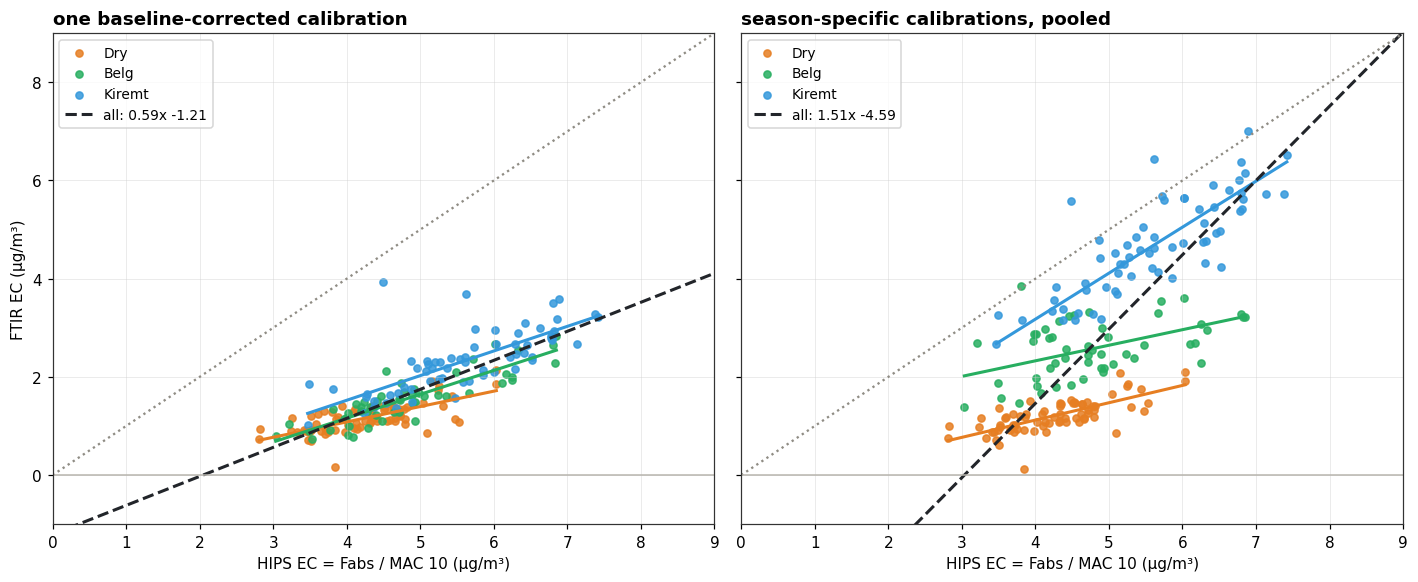

In [7]:
spl = P[('Addis', f'baseline-corrected, k {f_spl.k}')]
allp = pd.read_csv(M / 'addis_predictions.csv')
seas_pred = np.full(len(A), np.nan)
for s in SEASONS:
    q = allp[allp.fit_id.eq(f'seasonal|AIRSpec|locked|{s}') & allp.season.eq(s)].set_index('MediaId').ftir_ec_ugm3
    m = A.season.eq(s).to_numpy()
    seas_pred[m] = q.reindex(A.MediaId[m]).to_numpy()
assert np.isfinite(seas_pred).all()
rows = []
for s in SEASONS + ['All']:
    m = np.ones(len(A), bool) if s == 'All' else A.season.eq(s).to_numpy()
    st1 = addis_fit_sub = ab.xy_stats(A.hips.to_numpy()[m], spl[m], lam=ctx.lam, sigma_x=ctx.sigma_x, sigma_y=ab.SIGMA_Y_PROXY)
    st2 = ab.xy_stats(A.hips.to_numpy()[m], seas_pred[m], lam=ctx.lam, sigma_x=ctx.sigma_x, sigma_y=ab.SIGMA_Y_PROXY)
    rows.append({'season': s, 'n': int(m.sum()), 'mean HIPS EC': A.hips[m].mean(), 'HIPS IQR': np.subtract(*np.percentile(A.hips[m], [75, 25])),
                 'mean FTIR (one cal.)': spl[m].mean(), 'one cal.: slope': st1['deming_slope'], 'one cal.: intercept': st1['deming_intercept'],
                 'season cals: slope': st2['deming_slope'], 'season cals: intercept': st2['deming_intercept'], 'season cals: R2': st2['R2']})
E = pd.DataFrame(rows).set_index('season')
display(E.round(2))
mh = E.loc[SEASONS, 'mean HIPS EC'].to_numpy(); mf = E.loc[SEASONS, 'mean FTIR (one cal.)'].to_numpy()
print(f'between-season slope of the season means (Dry -> Kiremt): {(mf[-1] - mf[0]) / (mh[-1] - mh[0]):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), sharey=True)
for ax, y, ttl in ((axes[0], spl, 'one baseline-corrected calibration'), (axes[1], seas_pred, 'season-specific calibrations, pooled')):
    for s in SEASONS:
        m = A.season.eq(s).to_numpy()
        ax.scatter(A.hips[m], y[m], s=22, color=SCOL[s], alpha=.85, label=s.split()[0])
        st = ab.xy_stats(A.hips.to_numpy()[m], y[m], lam=ctx.lam, sigma_x=ctx.sigma_x, sigma_y=ab.SIGMA_Y_PROXY)
        xs = np.array([A.hips[m].min(), A.hips[m].max()])
        ax.plot(xs, st['deming_intercept'] + st['deming_slope'] * xs, color=SCOL[s], lw=2)
    st = ab.xy_stats(A.hips.to_numpy(), y, lam=ctx.lam, sigma_x=ctx.sigma_x, sigma_y=ab.SIGMA_Y_PROXY)
    xs = np.array([0, 9])
    ax.plot(xs, st['deming_intercept'] + st['deming_slope'] * xs, color='#22252A', lw=2, ls='--',
            label=f"all: {st['deming_slope']:.2f}x {st['deming_intercept']:+.2f}")
    ax.plot(xs, xs, ls=':', color=C_GREY); ax.axhline(0, color='#B8B5AE', lw=1)
    ax.set_xlim(0, 9); ax.set_ylim(-1, 9); ax.set_title(ttl, loc='left', fontweight='bold')
    ax.set_xlabel('HIPS EC = Fabs / MAC 10 (µg/m³)'); ax.legend(loc='upper left', fontsize=9)
axes[0].set_ylabel('FTIR EC (µg/m³)')
fig.tight_layout(); fig.savefig(FIG / 'E_seasons_pooled.png', dpi=200, bbox_inches='tight'); plt.show()

## Summary (21 Oct)

**C7: the "different direction" comes from comparing two calibrations, and from loading.**
* On the poster, Figure 4b (Addis) uses SPARTAN's raw-spectra calibration and Figure 5b (look-alikes) uses our
  baseline-corrected one. With the **same raw calibration** (SPARTAN-like, k 18), Addis is 2.36x - 6.30 while the
  look-alikes are 0.70x + 0.01: Addis is steep and offset, the look-alikes are not. With the **same baseline-corrected
  calibration**, both read low: Addis 0.59x - 1.21, look-alikes 0.46x + 0.11. Baselining makes the two sets fail in the
  same direction; only the small intercept differs in sign.
* In µg per filter (Section B) the look-alikes carry far less EC than Addis (median 7.8 µg against 34 µg); none reaches
  the Addis range. With the raw calibration, Addis leaves the look-alikes' line as loading rises. With the baselined
  calibration, Addis falls just below the look-alikes' line, extended.
* Raw spectra (Section C): Addis has a much higher sloping background (scattering from the heavier deposit) than the
  look-alikes, which the raw calibration reads as EC. The Teflon bands are the same.
* Baseline-corrected, **per µg of EC**, Addis carries about **one tenth** of the organic absorbance of its look-alikes
  (O–H 0.11, C–H 0.13, carbonyl 0.10, 1600 band 0.17 of the look-alike values). The look-alikes match the *shape* of the
  Addis organic spectrum, but not how much organic matter comes with each µg of EC. A calibration trained on IMPROVE
  reads EC partly through the organic bands that travel with it there, so it reads Addis low. (EC is HIPS Fabs / 10 for
  Addis and TOR for IMPROVE; a factor-of-two MAC error would not explain a factor of ten.)

**C8: why Kiremt works and Dry does not.**
* Per µg EC, the Addis organic bands relative to each season's IMPROVE look-alikes are lowest in Dry (0.07–0.12),
  higher in Belg (0.13–0.22) and highest in Kiremt (0.18–0.28). Kiremt's look-alikes are also the heaviest (13 µg EC on
  the filter, against 3.7 µg for Dry; Addis is 31–40 µg).
* So Kiremt is the season whose spectra carry the most organic signal per unit EC, the closest to what an IMPROVE
  calibration expects, with the closest look-alike loadings. Dry is the most EC-dominated: the least organic signal per
  µg EC, which an IMPROVE-trained calibration does not see. This fits Dry being diesel-dominated (low OC/EC), and it
  does not say that wood or charcoal smoke cannot be measured.
* Kiremt also keeps more residual absorbance at 3600–4000 cm⁻¹ after baselining (5.7 times its look-alikes), worth a
  look alongside the Christiansen-effect scattering Anwar (2025) reports for sulfate-rich Addis samples.

**C9: seasons separately vs together.**
* Within each season HIPS EC spans a narrow range (IQR about 1–1.5 µg/m³), and the within-season slopes are 0.31–0.50.
  The season means rise more steeply (Dry to Kiremt: 0.87). The fit of all seasons together mixes both, so its slope
  (0.59) is steeper than any single season's, and to pass through the overall centre a steeper line needs a more negative
  intercept (−1.21, against −0.17 to −0.78 within seasons).
* Pooling the three season-specific calibrations' predictions gives **1.51x − 4.59 (R² 0.55)**, worse than one
  calibration, because each season's calibration lands at a different level (Belg's intercept is +1.06).

**Next steps this points to:** pick IMPROVE calibration filters by EC fraction (low OC/EC, as Ann suggested) rather than
by spectral shape alone; check whether the Addis per-EC organic deficit holds with TOR-equivalent EC (MAC); and look at
the Kiremt high-wavenumber residual.